# Proporción de puntos seleccionados por la historia del residuo

Diez semillas pareadas, 100 pasos de calentamiento y 300 de continuación. Se mantiene un lote de 128 puntos y actualización cada 100 pasos. Sobol puro representa cero puntos elegidos por los modos.

QR básico está limitado por el rango retenido: aumentar su límite no garantiza más puntos. Aquí se conservan esas variantes y se añaden 32, 64 y 128 puntos mediante QR inicial seguido por selección voraz de ganancia log-det en los mismos modos. Esto es una extensión de la selección anterior, no una reproducción adicional del artículo QR-DEIM.

## Resultados al mismo presupuesto

| Variante | Puntos de modos reales (mín–máx) | RMSE (media ± DE) | Residuo RMS | Primer cruce | Bajo umbral al final |
|---|---:|---:|---:|---:|---:|
| Sobol (0 puntos de modos) | 0–0 | 0.3397 ± 0.0134 | 0.1995 | 7/10 | 7/10 |
| POD + QR por rango | 2–4 | 0.3428 ± 0.0131 | 0.1941 | 6/10 | 6/10 |
| POD: 32 puntos | 32–32 | 0.3456 ± 0.0172 | 0.1879 | 5/10 | 4/10 |
| POD: 64 puntos | 64–64 | 0.3418 ± 0.0188 | 0.1986 | 7/10 | 6/10 |
| POD: 128 puntos | 128–128 | 0.3505 ± 0.0206 | 0.2389 | 10/10 | 5/10 |
| PCA + media + QR por rango | 4–6 | 0.3414 ± 0.0136 | 0.1963 | 7/10 | 7/10 |
| PCA + media: 32 puntos | 32–32 | 0.3450 ± 0.0151 | 0.1906 | 5/10 | 5/10 |
| PCA + media: 64 puntos | 64–64 | 0.3389 ± 0.0153 | 0.2034 | 7/10 | 5/10 |
| PCA + media: 128 puntos | 128–128 | 0.3414 ± 0.0178 | 0.2454 | 10/10 | 6/10 |

El umbral es RMSE de validación ≤ 0.35, en el primer checkpoint observado; las semillas sin cruce son censuradas. El test no decide el umbral ni la selección.

## Comparación visual

**Fracción de puntos**

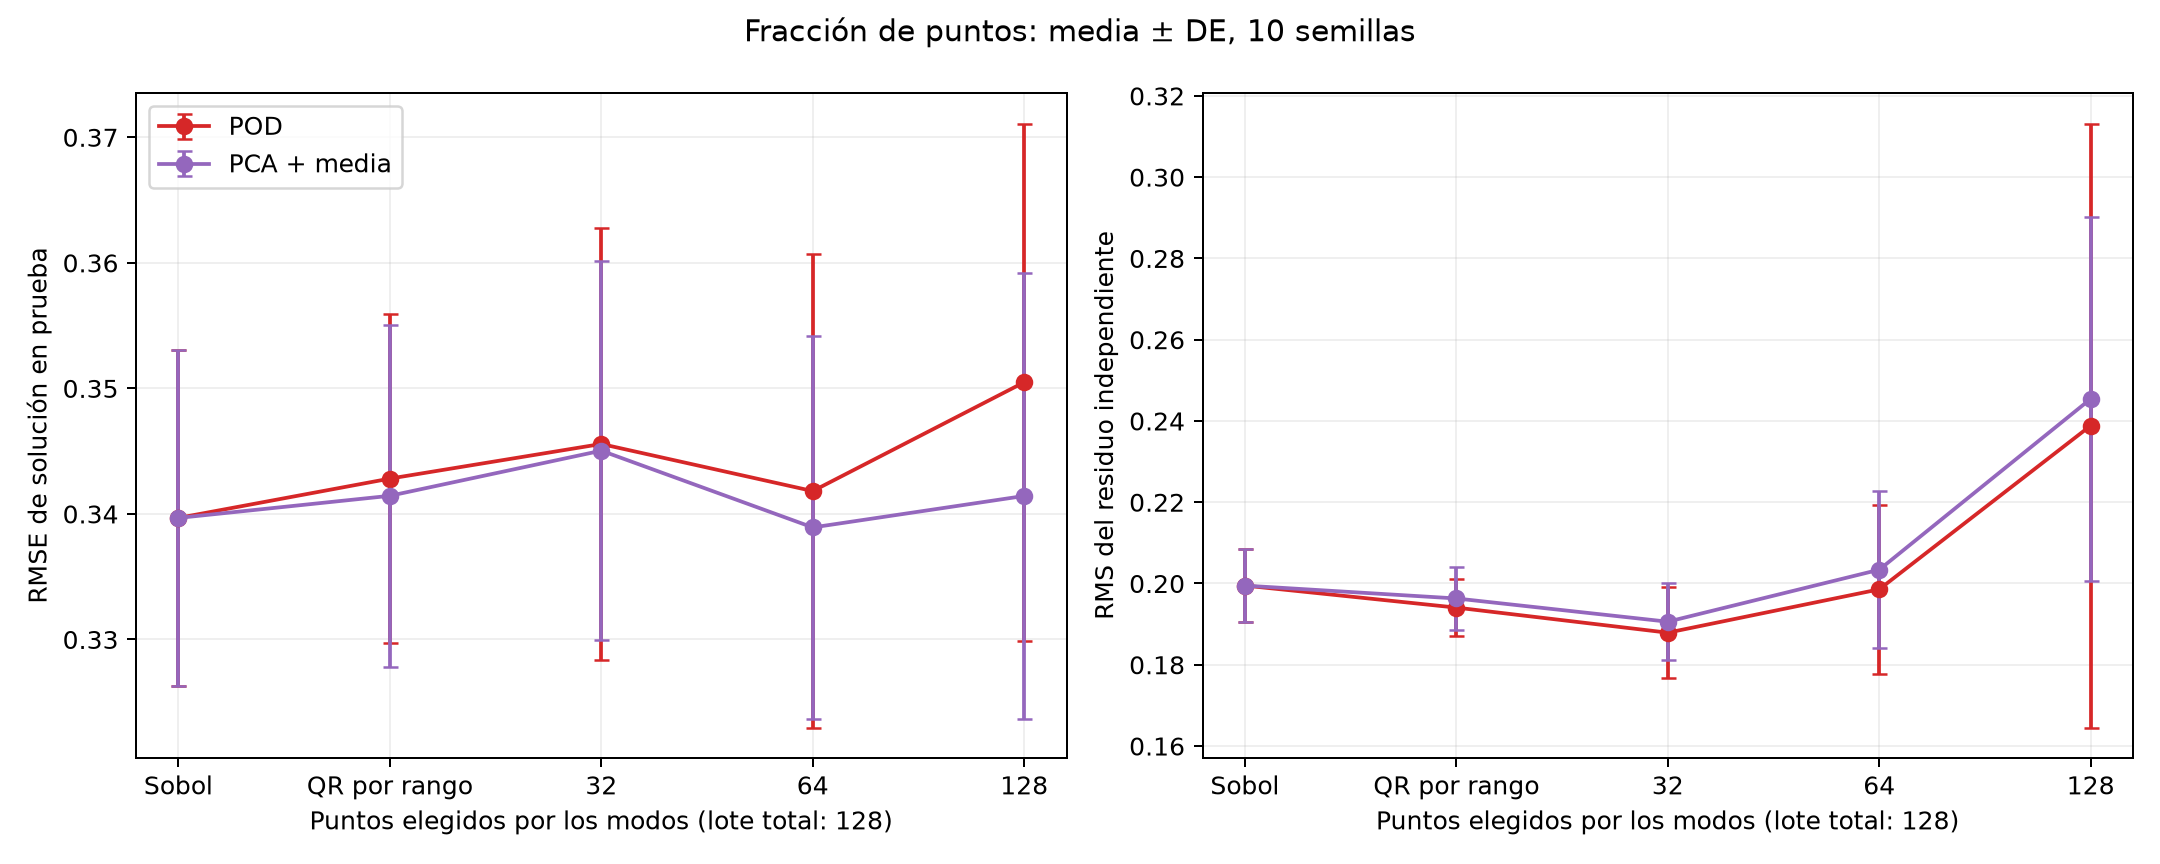

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/collocation_selection/qr_fraction_ablation_10_seeds_v1/fraction_ablation.png'), format='png', embed=True))


## Evolución de validación

**Validación**

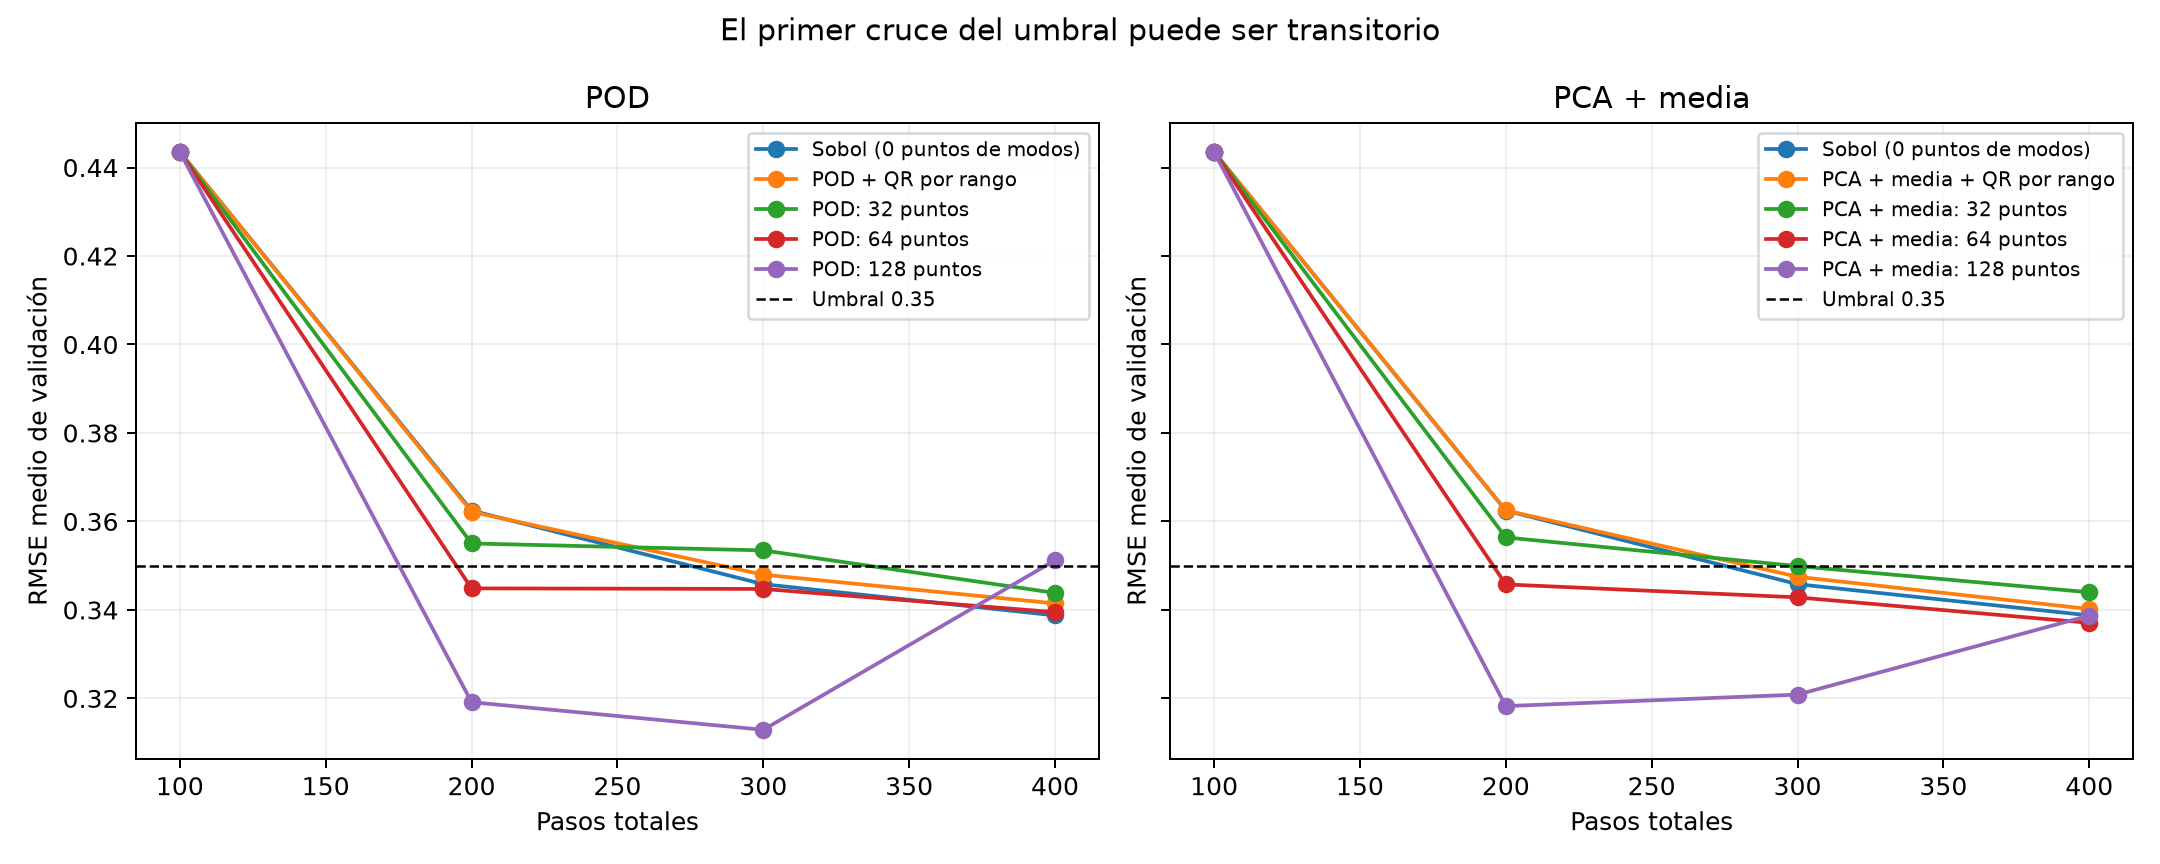

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/collocation_selection/qr_fraction_ablation_10_seeds_v1/fraction_validation.png'), format='png', embed=True))


Un primer cruce cuenta incluso si el entrenamiento posterior empeora. La tabla distingue ese evento de terminar bajo el umbral.

## Interpretación y límites

El número de puntos seleccionados se registra en cada actualización; las 32/64/128 filas elegidas son índices distintos del conjunto candidato. El número de modos sigue fijado por energía de 0.99 y máximo 20. El complemento usa el mismo prefijo Sobol por semilla y actualización, también compartido entre POD y PCA.

Las diferencias pareadas se guardan frente a Sobol y frente al QR limitado por rango de cada enfoque. Un menor residuo independiente debe acompañarse de mejora en la solución y las condiciones iniciales y de frontera. El presupuesto corto limita las conclusiones. Los tiempos incluyen evaluaciones y compilación inicial; no se usan para afirmar aceleración.

In [ ]:
import json
from pathlib import Path
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists())
output = root / 'pca_collocation/results/burgers/collocation_selection/qr_fraction_ablation_10_seeds_v1'
summary = json.loads((output / 'summary.json').read_text(encoding='utf-8'))
summary['methods']